In [1]:
import yfinance as yf
import pandas as pd

# Descargar datos de AAPL desde Yahoo Finance
data = yf.download('AAPL', start='2010-01-01', end='2022-01-01')

# Mostrar las primeras filas del DataFrame
data.head()

[*********************100%%**********************]  1 of 1 completed


/home/suarenguen/anaconda3/lib/python3.11/site-packages/yfinance/utils.py:788: FutureWarning: The 'unit' keyword in TimedeltaIndex construction is deprecated and will be removed in a future version. Use pd.to_timedelta instead.
  df.index += _pd.TimedeltaIndex(dst_error_hours, 'h')


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-01-04,7.622500,7.660714,7.585000,7.643214,6.454505,493729600
2010-01-05,7.664286,7.699643,7.616071,7.656429,6.465663,601904800
2010-01-06,7.656429,7.686786,7.526786,7.534643,6.362819,552160000
2010-01-07,7.562500,7.571429,7.466071,7.520714,6.351056,477131200
2010-01-08,7.510714,7.571429,7.466429,7.570714,6.393280,447610800


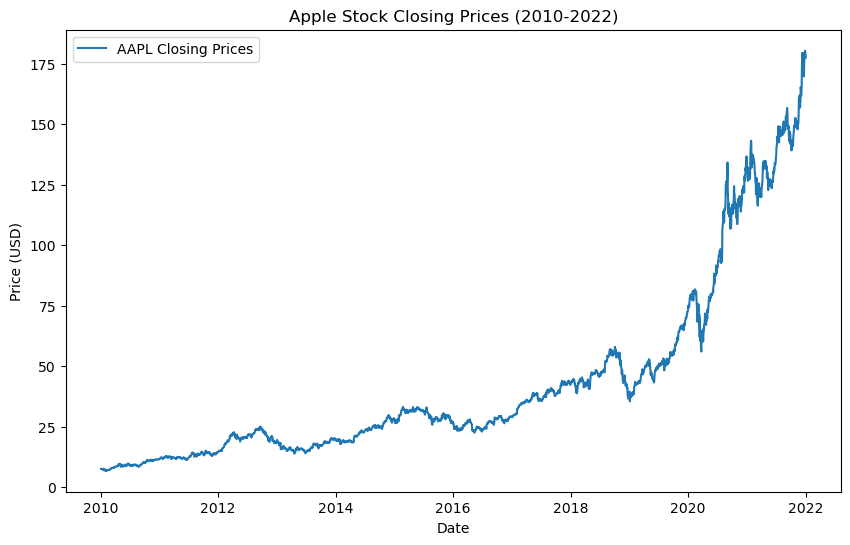

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(data['Close'], label='AAPL Closing Prices')
plt.title('Apple Stock Closing Prices (2010-2022)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

In [3]:
mean_price = data['Close'].mean()
std_price = data['Close'].std()

print(f"Mean Price: {mean_price}")
print(f"Standard Deviation: {std_price}")

Mean Price: 42.72072799282333
Standard Deviation: 38.084410458575185


In [4]:
import numpy as np

def create_sequences(data, time_steps=60):
    sequences = []
    targets = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
        targets.append(data[i + time_steps])
    return np.array(sequences), np.array(targets)

# Crear secuencias y objetivos
close_prices = data['Close'].values
X, y = create_sequences(close_prices, 60)

In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
close_prices_scaled = scaler.fit_transform(close_prices.reshape(-1, 1))

# Crear secuencias con los precios normalizados
X_scaled, y_scaled = create_sequences(close_prices_scaled, 60)

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, InputLayer
import tensorflow as tf
tf.random.set_seed(42)
# Definir el modelo RNN
rnn_model = Sequential()
rnn_model.add(InputLayer(input_shape=(60, 1)))
rnn_model.add(SimpleRNN(units=10, activation='relu', return_sequences=False))
rnn_model.add(Dense(units=1))

rnn_model.compile(optimizer='adam', loss='mean_squared_error')

2024-09-06 16:26:53.967800: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-09-06 16:26:56.752381: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [7]:
from tensorflow.keras.layers import LSTM

# Definir el modelo LSTM
lstm_model = Sequential()
rnn_model.add(InputLayer(input_shape=(60, 1)))
lstm_model.add(LSTM(units=2, activation='relu', return_sequences=False))
lstm_model.add(Dense(units=1))

lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [8]:
# Dividir los datos en conjunto de entrenamiento y prueba
split = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split], X_scaled[split:]
y_train, y_test = y_scaled[:split], y_scaled[split:]

# Entrenar el modelo RNN
rnn_history = rnn_model.fit(X_train, y_train, epochs=5, batch_size=16)

Epoch 1/5
  1/148 [..............................] - ETA: 2:25 - loss: 0.0116

2024-09-06 16:26:57.879872: W tensorflow/core/grappler/utils/graph_view.cc:849] No registered '' OpKernel for CPU devices compatible with node {{node sequential/simple_rnn/while/body/_1/sequential/simple_rnn/while/simple_rnn_cell/Relu}}
	.  Registered:  <no registered kernels>

2024-09-06 16:26:57.907572: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: Node sequential/simple_rnn/while/body/_1/sequential/simple_rnn/while/simple_rnn_cell/Relu has an empty op name
	when importing GraphDef to MLIR module in GrapplerHook
2024-09-06 16:26:57.939450: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-functional-to-region,tfg.func(tfg-cf-sink),tfg-region-to-functional{force-control-capture=true},tfg-lift-legacy-call,symbol-privatize{},symbol-dce,tfg-prepare-attrs-export)} failed:

148/148 [==============================] - 2s 9ms/step - loss: 0.0022
Epoch 2/5
148/148 [==============================] - 1s 9ms/step - loss: 4.3665e-04
Epoch 3/5
148/148 [==============================] - 2s 10ms/step - loss: 2.9761e-05
Epoch 4/5
148/148 [==============================] - 1s 10ms/step - loss: 9.2083e-06
Epoch 5/5
148/148 [==============================] - 1s 9ms/step - loss: 8.4255e-06


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rnn_loss = rnn_model.evaluate(X_test, y_test)
predictions = rnn_model.predict(X_test)

# Invertir la normalización de las predicciones y valores reales
predictions = scaler.inverse_transform(predictions)
y_test_inv = scaler.inverse_transform(y_test)
r2 = r2_score(y_test_inv, predictions)
# lstm_loss = lstm_model.evaluate(X_test, y_test)

print(f"RNN Test Loss: {rnn_loss}")
print(f"R² Score: {r2}")
# print(f"LSTM Test Loss: {lstm_loss}")

19/19 [==============================] - 1s 16ms/step
RNN Test Loss: 0.002574082463979721
R² Score: 0.9324765583814772


dict_keys(['loss'])


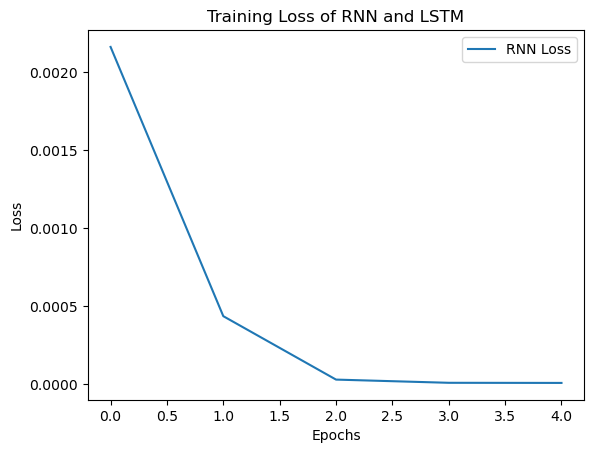

In [10]:
# Verificar si 'loss' está disponible en el historial
print(rnn_history.history.keys())
# print(lsm_history.history.keys())

# Graficar las pérdidas de entrenamiento
plt.plot(rnn_history.history['loss'], label='RNN Loss')
# plt.plot(lsm_history.history['loss'], label='LSTM Loss')
plt.legend()
plt.title('Training Loss of RNN and LSTM')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [19]:
from tensorflow.keras.callbacks import EarlyStopping
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import RandomizedSearchCV
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import numpy as np
import os
import tensorflow as tf

# Cambiar el nivel de registro a 2 para eliminar mensajes de información (INFO) y advertencias no importantes
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Opciones: 0 = todos, 1 = advertencias, 2 = errores, 3 = solo errores críticos

# Activar el ejecutor legacy para evitar mensajes de depuración innecesarios

# Definir el modelo LSTM
def build_lstm_model(units=30, learning_rate=0.001): 
    model = Sequential()
    model.add(SimpleRNN(units=units, activation='tanh', input_shape=(60, 1)))
    model.add(Dense(units=1))
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error')
    return model

# Crear el KerasRegressor
lstm_model = KerasRegressor(model=build_lstm_model, verbose=1)

# Definir los parámetros del random search
param_distributions = {
    'model__units': [10, 20, 50],  
    'batch_size': [16, 32],
    'epochs': [5, 10],
    'model__learning_rate': [0.001, 0.01]
}

# Configurar el callback de EarlyStopping
early_stopping = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)

# Realizar el RandomizedSearchCV con el callback de EarlyStopping
random_search = RandomizedSearchCV(estimator=lstm_model, param_distributions=param_distributions, 
                                   n_iter=10,  # Número de combinaciones a probar
                                   scoring='neg_mean_squared_error', 
                                   cv=2, 
                                   random_state=42)

# Ajustar el modelo con los datos de entrenamiento y el callback
random_search_result = random_search.fit(X_train, y_train, callbacks=[early_stopping])

# Mostrar los mejores hiperparámetros y la pérdida en el conjunto de prueba
print("Best Hyperparameters: ", random_search_result.best_params_)
best_model = random_search_result.best_estimator_
test_loss = best_model.score(X_test, y_test)
print(f"Test Loss of the Best Model: {test_loss}")

Epoch 1/10
74/74 [==============================] - 5s 61ms/step - loss: 0.0012
Epoch 2/10
74/74 [==============================] - 5s 66ms/step - loss: 7.9074e-05
Epoch 3/10
74/74 [==============================] - 3s 44ms/step - loss: 6.9075e-05
Epoch 4/10
74/74 [==============================] - 4s 56ms/step - loss: 5.9561e-05
Epoch 5/10
74/74 [==============================] - 4s 52ms/step - loss: 5.5207e-05
Epoch 6/10
74/74 [==============================] - 3s 46ms/step - loss: 5.3950e-05
Epoch 7/10
74/74 [==============================] - 3s 44ms/step - loss: 6.0450e-05
Epoch 8/10
74/74 [==============================] - 3s 42ms/step - loss: 4.6703e-05
Epoch 9/10
74/74 [==============================] - 4s 54ms/step - loss: 4.5295e-05
Epoch 10/10
74/74 [==============================] - 2s 28ms/step
Epoch 1/10
74/74 [==============================] - 6s 66ms/step - loss: 3.0128e-04
Epoch 2/10
74/74 [==============================] - 4s 56ms/step - loss: 1.7853e-05
Epoch 3/10
74/

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, InputLayer

# Definir el modelo RNN
rnn_model_tunned = Sequential()
rnn_model_tunned.add(InputLayer(input_shape=(60, 1)))
rnn_model_tunned.add(SimpleRNN(units=10, activation='relu', return_sequences=False))
rnn_model_tunned.add(Dense(units=1))

rnn_model_tunned.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
split = int(0.8 * len(X_scaled))
X_train, X_test = X_scaled[:split], X_scaled[split:]
y_train, y_test = y_scaled[:split], y_scaled[split:]

# Entrenar el modelo RNN
rnn_history_tunned = rnn_model_tunned.fit(X_train, y_train, epochs=10, batch_size=16)

Epoch 1/10
  7/148 [>.............................] - ETA: 1s - loss: 0.0062  

2024-09-06 16:41:38.100029: W tensorflow/core/grappler/utils/graph_view.cc:849] No registered '' OpKernel for CPU devices compatible with node {{node sequential_24/simple_rnn_23/while/body/_1/sequential_24/simple_rnn_23/while/simple_rnn_cell_23/Relu}}
	.  Registered:  <no registered kernels>

2024-09-06 16:41:38.136004: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: Node sequential_24/simple_rnn_23/while/body/_1/sequential_24/simple_rnn_23/while/simple_rnn_cell_23/Relu has an empty op name
	when importing GraphDef to MLIR module in GrapplerHook
2024-09-06 16:41:38.170572: E tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:134] tfg_optimizer{any(tfg-consolidate-attrs,tfg-functional-to-region,tfg.func(tfg-cf-sink),tfg-region-to-functional{force-control-capture=true},tfg-lift-legacy-call,symbol-privatize{},symbol-dce,tfg-

 66/148 [============>.................] - ETA: 0s - loss: 0.0018

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rnn_loss_tunned = rnn_model_tunned.evaluate(X_test, y_test)
predictions_tunned = rnn_model_tunned.predict(X_test)

# Invertir la normalización de las predicciones y valores reales
predictions_tunned = scaler.inverse_transform(predictions_tunned)
y_test_inv_tunned = scaler.inverse_transform(y_test)
r2_tunned = r2_score(y_test_inv_tunned, predictions_tunned)
# lstm_loss = lstm_model.evaluate(X_test, y_test)

print(f"RNN Tunned Test Loss: {rnn_loss}")
print(f"R² Tunned Score: {r2}")

print(f"RNN Tunned Test Loss: {rnn_loss_tunned}")
print(f"R² Tunned Score: {r2_tunned}")

19/19 [==============================] - 1s 31ms/step
RNN Tunned Test Loss: 0.002574082463979721
R² Tunned Score: 0.9324765583814772
RNN Tunned Test Loss: 0.002105018589645624
R² Tunned Score: 0.9447810666835289


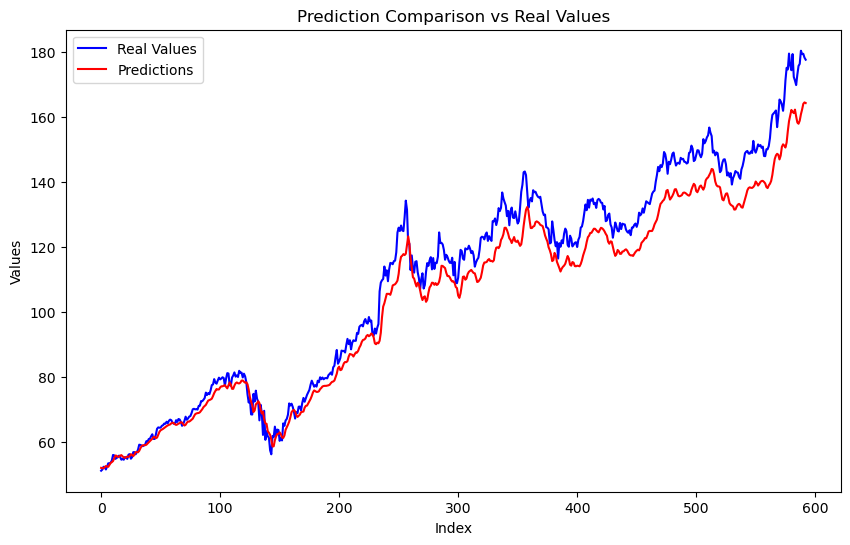

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(y_test_inv_tunned, label='Real Values', color='blue')
plt.plot(predictions_tunned, label='Predictions', color='red')
plt.title('Prediction Comparison vs Real Values')
plt.xlabel('Index')
plt.ylabel('Values')
plt.legend()
plt.show()